# Actividad de Evaluación 1 · Unidad II
## Exploración, clasificación y diagnóstico del conjunto de datos

**Universidad Tecnológica de Tula-Tepeji**  
**Asignatura:** Extracción de Conocimiento en Bases de Datos — Recursamiento 2026  
**Docente:** Ing. Jose Luis Herrera Gallardo, MTI  
**Alumno:** David Rafael Aguilar Solis · **Matrícula:** 22300607 · **Grupo:** 10IDGS-G1  
**Proyecto:** Análisis de hábitos y condición física asociados con niveles de obesidad  
**Fuente:** UCI Machine Learning Repository, dataset 544

**Alcance:** exploración de solo lectura sobre el CSV original. No se eliminan filas, no se imputan datos, no se transforman las variables ni se escribe en `data/raw/`. Las operaciones numéricas se utilizan únicamente para diagnosticar y visualizar. La aprobación académica está sujeta a la revisión del docente.

### Guía rápida de ejecución

1. Abrir el repositorio en VS Code y este notebook dentro de `notebooks/`.
2. Elegir un kernel Python con `pandas`, `numpy` y `matplotlib` instalados.
3. Ejecutar **Run All**. El notebook busca `data/raw/ObesityDataSet_raw_and_data_sinthetic.csv` desde la carpeta de trabajo o sus directorios padres, sin requerir rutas absolutas.
4. Consultar cada interpretación inmediatamente después de sus resultados. Para defender la actividad, explicar las instrucciones `head`, `shape`, `info`, `describe`, `isnull` y `duplicated`.

Los resultados incluidos fueron ejecutados con el CSV original. Al cambiar el dataset, deben recalcularse las interpretaciones.

## 1. Identificación del dataset y procedencia

In [1]:
from pathlib import Path
from hashlib import sha256
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CSV_NAME = 'ObesityDataSet_raw_and_data_sinthetic.csv'
CANDIDATOS = [p / 'data' / 'raw' / CSV_NAME for base in (Path.cwd(), *Path.cwd().parents) for p in (base,)]
CANDIDATOS.append(Path.cwd() / CSV_NAME)  # Solo apoyo para validar un CSV montado sin repositorio
ruta_csv = next((p for p in CANDIDATOS if p.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError('Coloca este notebook en notebooks/ dentro del repositorio que contiene data/raw/' + CSV_NAME)

raw_bytes = ruta_csv.read_bytes()
sha_original = sha256(raw_bytes).hexdigest()
df = pd.read_csv(ruta_csv)  # Lectura: no se modifica el original.
print('Archivo:', ruta_csv)
print('Formato:', ruta_csv.suffix.upper())
print('Registros:', len(df))
print('Variables:', df.shape[1])
print('SHA-256 original:', sha_original)
print('Categorías objetivo:', df['NObeyesdad'].nunique())

Archivo: C:\Users\rafle\Documents\REC_ECBD_2026_Aguilar_Solis_David_Rafael\data\raw\ObesityDataSet_raw_and_data_sinthetic.csv
Formato: .CSV
Registros: 2111
Variables: 17
SHA-256 original: 28b6991062855d3d15642e38b1aa9d1b32fb7abbb5abf5b096f1868cd706154b
Categorías objetivo: 7


**Interpretación.** Se estudia un archivo **CSV estructurado** de hábitos alimentarios, características antropométricas, actividad física y nivel de obesidad. Contiene **2,111 registros y 17 variables** (16 posibles características explicativas y la etiqueta `NObeyesdad`). La huella SHA-256 permite comprobar que se está usando el mismo archivo original durante toda la actividad. El dataset corresponde a [UCI 544](https://doi.org/10.24432/C5H31Z).

## 2. Carga y exploración inicial con Pandas

### 2.1 `df.head()` — primeras observaciones

In [2]:
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


**Interpretación.** Muestra cinco filas y permite reconocer las columnas y ejemplos de sus valores: `Gender`, `Age`, `Height`, `Weight`, hábitos, transporte y `NObeyesdad`. No representa la totalidad del dataset ni demuestra por sí sola ausencia de errores.

### 2.2 `df.shape` — dimensiones

In [3]:
df.shape

(2111, 17)

**Interpretación.** La tupla `(2111, 17)` significa **2,111 filas y 17 columnas**. No se debe confundir el número de columnas con la cantidad de categorías de obesidad.

### 2.3 `df.columns` — encabezados

In [4]:
df.columns

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight',
       'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE',
       'CALC', 'MTRANS', 'NObeyesdad'],
      dtype='str')

**Interpretación.** Permite comprobar los nombres exactos y su orden. La etiqueta `NObeyesdad` es una de las 17 columnas, mientras que las otras 16 representan características y respuestas del cuestionario.

### 2.4 `df.info()` — tipos y completitud

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   str    
 12  FAF                             2111 non-null

**Interpretación.** Pandas identifica **8 columnas numéricas `float64` y 9 columnas de texto `object`**. La vista también informa cuántas entradas no nulas tiene cada variable; aquí todas tienen 2,111. `object` indica representación textual en Python, no que la variable carezca de significado estadístico.

### 2.5 `df.dtypes` — tipo técnico por columna

In [6]:
df.dtypes

Gender                                str
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight        str
FAVC                                  str
FCVC                              float64
NCP                               float64
CAEC                                  str
SMOKE                                 str
CH2O                              float64
SCC                                   str
FAF                               float64
TUE                               float64
CALC                                  str
MTRANS                                str
NObeyesdad                            str
dtype: object

**Interpretación.** El tipo técnico (`float64`/`object`) no es idéntico a la clasificación conceptual (cuantitativa, cualitativa, nominal, ordinal). Algunas escalas numéricas contienen decimales, aunque representen respuestas codificadas.

### 2.6 `df.describe()` — estadística descriptiva

In [7]:
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


**Interpretación.** Resume conteo, media, desviación estándar, mínimo, cuartiles y máximo de las variables numéricas. Por ejemplo, la edad media es aproximadamente **24.31 años** y el peso medio **86.59 kg**. Se complementa con un perfil de las variables cualitativas:

In [8]:
df.describe(include=['object'])

C:\Users\rafle\AppData\Local\Temp\ipykernel_24244\3011300674.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['object'])


,Gender,family_history_with_overweight,FAVC,CAEC,SMOKE,SCC,CALC,MTRANS,NObeyesdad
count,2111,2111,2111,2111,2111,2111,2111,2111,2111
unique,2,2,2,4,2,2,4,5,7
top,Male,yes,yes,Sometimes,no,no,Sometimes,Public_Transportation,Obesity_Type_I
freq,1068,1726,1866,1765,2067,2015,1401,1580,351


**Interpretación complementaria.** Para columnas categóricas se muestran cantidad de respuestas válidas, categorías diferentes, moda y frecuencia de la moda. Estos resultados describen el archivo, no la prevalencia de obesidad en la población general.

## 3. Diccionario de datos completo (17 variables)

In [9]:
metadata = [
 ('Gender','Género registrado','Cualitativa','Nominal (dos opciones)','No aplica','Describir composición; posible predictor'),
 ('Age','Edad','Cuantitativa','Continua en el CSV','Años','Exploración, regresión y clustering'),
 ('Height','Estatura','Cuantitativa','Continua','Metros (m)','Descripción y regresión; riesgo de fuga en clasificación'),
 ('Weight','Peso corporal','Cuantitativa','Continua','Kilogramos (kg)','Objetivo de regresión; riesgo de fuga en clasificación'),
 ('family_history_with_overweight','Antecedentes familiares de sobrepeso','Cualitativa','Binaria (sí/no)','No aplica','Variable explicativa de hábitos y clasificación'),
 ('FAVC','Consumo habitual de alimentos hipercalóricos','Cualitativa','Binaria (sí/no)','No aplica','Analizar hábitos alimentarios'),
 ('FCVC','Frecuencia de consumo de verduras','Cuantitativa codificada','Ordinal / escala 1–3','Escala 1–3','Caracterizar alimentación; contiene fracciones'),
 ('NCP','Número aproximado de comidas principales','Cuantitativa codificada','Cuenta/escala 1–4','Comidas/escala','Caracterizar hábitos; contiene fracciones'),
 ('CAEC','Alimentos entre comidas','Cualitativa','Ordinal','Frecuencia','Hábitos y patrones de consumo'),
 ('SMOKE','Fuma','Cualitativa','Binaria (sí/no)','No aplica','Caracterizar hábitos'),
 ('CH2O','Consumo diario de agua codificado','Cuantitativa codificada','Ordinal / escala 1–3','Escala 1–3','Consumo de agua y agrupamiento'),
 ('SCC','Monitoreo del consumo de calorías','Cualitativa','Binaria (sí/no)','No aplica','Caracterizar autocontrol alimentario'),
 ('FAF','Frecuencia de actividad física codificada','Cuantitativa codificada','Ordinal / escala 0–3','Escala 0–3','Actividad física y clustering'),
 ('TUE','Uso de dispositivos tecnológicos codificado','Cuantitativa codificada','Ordinal / escala 0–2','Escala 0–2','Hábitos sedentarios y clustering'),
 ('CALC','Frecuencia de consumo de alcohol','Cualitativa','Ordinal','Frecuencia','Caracterizar consumo de alcohol'),
 ('MTRANS','Medio habitual de transporte','Cualitativa','Nominal','No aplica','Caracterizar movilidad'),
 ('NObeyesdad','Categoría de nivel de obesidad','Cualitativa','Ordinal (clases ordenables)','Categoría','Objetivo de clasificación de siete clases'),
]
diccionario = pd.DataFrame(metadata, columns=['Variable','Descripción','Tipo de variable','Clasificación','Unidad de medida','Posible utilidad'])
diccionario.insert(2, 'Tipo en Python', diccionario['Variable'].map(lambda c: str(df[c].dtype)))
assert set(diccionario['Variable']) == set(df.columns) and len(diccionario) == 17
pd.set_option('display.max_colwidth', 80)
display(diccionario)

,Variable,Descripción,Tipo en Python,Tipo de variable,Clasificación,Unidad de medida,Posible utilidad
0,Gender,Género registrado,str,Cualitativa,Nominal (dos opciones),No aplica,Describir composición; posible predictor
1,Age,Edad,float64,Cuantitativa,Continua en el CSV,Años,"Exploración, regresión y clustering"
2,Height,Estatura,float64,Cuantitativa,Continua,Metros (m),Descripción y regresión; riesgo de fuga en clasificación
3,Weight,Peso corporal,float64,Cuantitativa,Continua,Kilogramos (kg),Objetivo de regresión; riesgo de fuga en clasificación
4,family_history_with_overweight,Antecedentes familiares de sobrepeso,str,Cualitativa,Binaria (sí/no),No aplica,Variable explicativa de hábitos y clasificación
5,FAVC,Consumo habitual de alimentos hipercalóricos,str,Cualitativa,Binaria (sí/no),No aplica,Analizar hábitos alimentarios
6,FCVC,Frecuencia de consumo de verduras,float64,Cuantitativa codificada,Ordinal / escala 1–3,Escala 1–3,Caracterizar alimentación; contiene fracciones
7,NCP,Número aproximado de comidas principales,float64,Cuantitativa codificada,Cuenta/escala 1–4,Comidas/escala,Caracterizar hábitos; contiene fracciones
8,CAEC,Alimentos entre comidas,str,Cualitativa,Ordinal,Frecuencia,Hábitos y patrones de consumo
9,SMOKE,Fuma,str,Cualitativa,Binaria (sí/no),No aplica,Caracterizar hábitos


**Interpretación.** Todas las variables están documentadas con **nombre, significado, tipo técnico, tipo estadístico, clasificación, unidad y utilidad**. `NObeyesdad` tiene siete clases ordenables; `Gender` y `MTRANS` son nominales. `FCVC`, `NCP`, `CH2O`, `FAF` y `TUE` contienen valores fraccionarios en el archivo por la componente sintética y **no deben redondearse automáticamente**.

Los rangos observados no equivalen a límites médicos. La clasificación de escalas refleja la documentación de UCI y las particularidades del archivo recibido.

## 4. Tipo y fuente de los datos

- **Origen primario documentado:** plataforma web/cuestionario sobre hábitos alimentarios y condición física de participantes de México, Perú y Colombia.
- **Composición declarada por UCI:** alrededor de **23% de respuestas recolectadas y 77% de observaciones sintéticas** generadas con Weka/SMOTE. No existe en este CSV una columna que identifique individualmente cuáles filas son sintéticas.
- **Tipo de fuente:** datos originalmente aportados por personas mediante web y complementados con generación algorítmica. No son registros de transacciones ni lecturas directas de sensores.
- **Estructura:** **estructurados**, almacenados en una tabla CSV de 17 columnas con nombres y tipos interpretables.
- **Alcance:** descripción de este dataset, sin atribuir causalidad ni extrapolar estimaciones a una población real.

## 5. Diagnóstico de calidad

### 5.1 Valores faltantes

In [10]:
faltantes = df.isnull().sum()  # Instrucción exigida
faltantes_pct = 100 * faltantes / len(df)
resumen_faltantes = pd.DataFrame({'Faltantes': faltantes, 'Porcentaje (%)': faltantes_pct.round(2)})
display(resumen_faltantes)
print('Total de celdas faltantes:', int(faltantes.sum()))

,Faltantes,Porcentaje (%)
Gender,0,0.0
Age,0,0.0
Height,0,0.0
Weight,0,0.0
family_history_with_overweight,0,0.0
FAVC,0,0.0
FCVC,0,0.0
NCP,0,0.0
CAEC,0,0.0
SMOKE,0,0.0


Total de celdas faltantes: 0


**Interpretación.** Se observaron **cero celdas faltantes** en las 17 variables. No se requiere imputación en esta muestra. Si aparecieran faltantes en datos futuros, la estrategia debería decidirse durante el entrenamiento y justificarse según el tipo de variable; en esta actividad no se imputan valores.

### 5.2 Duplicados

In [11]:
duplicados = int(df.duplicated().sum())
porcentaje_duplicados = 100 * duplicados / len(df)
print('Filas exactamente duplicadas:', duplicados)
print('Porcentaje de filas duplicadas sobre el total:', f'{porcentaje_duplicados:.2f}%')
print('Filas conservadas:', len(df))

Filas exactamente duplicadas: 24
Porcentaje de filas duplicadas sobre el total: 1.14%
Filas conservadas: 2111


**Interpretación.** Se detectaron **24 filas repetidas exactamente** respecto a una fila anterior, equivalentes al **1.14% de las 2,111 filas** según `df.duplicated().sum() / len(df)`. El porcentaje cuenta las repeticiones posteriores que marca Pandas, no todos los miembros de cada grupo de duplicados. El archivo no ofrece un identificador único de participante; podrían responder a registros idénticos o a generación sintética. **No se eliminan**. En modelado posterior, se deben agrupar filas idénticas antes de dividir entrenamiento y prueba para evitar fugas de información.

### 5.3 Inconsistencias, rangos y categorías

In [12]:
rangos_esperados = {'Age': (0, 120), 'Height': (0, np.inf), 'Weight': (0, np.inf),
                    'FCVC': (1, 3), 'NCP': (1, 4), 'CH2O': (1, 3),
                    'FAF': (0, 3), 'TUE': (0, 2)}
incidencias = {}
for col, (mini, maxi) in rangos_esperados.items():
    valor = df[col]
    if col in ('Height','Weight'):
        fuera = (valor <= mini) | (~np.isfinite(valor))
    else:
        fuera = (valor < mini) | (valor > maxi) | (~np.isfinite(valor))
    incidencias[col] = int(fuera.sum())

dominios = {
  'Gender': {'Female','Male'}, 'family_history_with_overweight': {'yes','no'},
  'FAVC': {'yes','no'}, 'SMOKE': {'yes','no'}, 'SCC': {'yes','no'},
  'CAEC': {'no','Sometimes','Frequently','Always'},
  'CALC': {'no','Sometimes','Frequently','Always'},
  'MTRANS': {'Automobile','Motorbike','Bike','Public_Transportation','Walking'},
  'NObeyesdad': {'Insufficient_Weight','Normal_Weight','Overweight_Level_I',
                'Overweight_Level_II','Obesity_Type_I','Obesity_Type_II','Obesity_Type_III'}
}
for col, valores_validos in dominios.items():
    incidencias[col] = int((~df[col].isin(valores_validos)).sum())
display(pd.DataFrame({'Variable': list(incidencias), 'Valores fuera de dominio/rango de trabajo': list(incidencias.values())}))

columnas_numericas = {'Age','Height','Weight','FCVC','NCP','CH2O','FAF','TUE'}
columnas_categoricas = set(df.columns) - columnas_numericas
tipos_inesperados = {
    col: str(df[col].dtype) for col in df.columns
    if (col in columnas_numericas and not pd.api.types.is_numeric_dtype(df[col]))
    or (col in columnas_categoricas and not (pd.api.types.is_object_dtype(df[col]) or pd.api.types.is_string_dtype(df[col])))
}
print('Columnas con tipo técnico inesperado:', tipos_inesperados)
print('Suma de incidencias por controles de dominio/rango:', sum(incidencias.values()))

,Variable,Valores fuera de dominio/rango de trabajo
0,Age,0
1,Height,0
2,Weight,0
3,FCVC,0
4,NCP,0
5,CH2O,0
6,FAF,0
7,TUE,0
8,Gender,0
9,family_history_with_overweight,0


Columnas con tipo técnico inesperado: {}
Suma de incidencias por controles de dominio/rango: 0


**Interpretación.** Los controles básicos de positividad, intervalos de escala y categorías registradas **no identificaron valores fuera de los dominios de trabajo**. También se compararon los ocho campos numéricos y nueve categóricos con sus tipos técnicos esperados; no se convirtieron columnas. Los intervalos empleados son controles de plausibilidad y codificación, no criterios clínicos. La procedencia sintética exige revisar también valores fraccionarios, que pueden resultar extraños sin ser errores.

In [13]:
escalas = ['FCVC','NCP','CH2O','FAF','TUE']
fraccionarios = pd.DataFrame({'Variable': escalas,
 'Con parte decimal': [int(((df[c]-df[c].round()).abs()>1e-9).sum()) for c in escalas]})
display(fraccionarios)

,Variable,Con parte decimal
0,FCVC,826
1,NCP,640
2,CH2O,1290
3,FAF,1208
4,TUE,1153


**Interpretación.** Las escalas tienen fracciones en parte de las filas; para este dataset, una explicación plausible es la generación sintética/interpolación. No se corregirán mediante redondeo porque cambiaríamos valores originales sin una regla validada.

## 6. Análisis estadístico inicial

In [14]:
variables_num = ['Age','Height','Weight']
estadisticos = df[variables_num].agg(['mean','median','min','max','std']).T
estadisticos.columns = ['Media','Mediana','Mínimo','Máximo','Desv. estándar']
display(estadisticos.round(3))

,Media,Mediana,Mínimo,Máximo,Desv. estándar
Age,24.313,22.778,14.00,61.00,6.346
Height,1.702,1.700,1.45,1.98,0.093
Weight,86.586,83.000,39.00,173.00,26.191


**Interpretación.** La muestra presenta edad media de **24.31 años** (rango 14–61), estatura media de **1.702 m** (rango 1.45–1.98) y peso medio de **86.59 kg** (rango 39–173). La dispersión del peso (desviación estándar ≈ **26.19 kg**) es considerable, lo que motiva explorar su distribución. Estas medidas describen registros de un dataset parcialmente sintético y no sirven para estimar prevalencias poblacionales.

## 7. Identificación de posibles valores atípicos (1.5 × IQR)

In [15]:
def diagnostico_iqr(serie):
    q1, q3 = serie.quantile([.25, .75])
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {'Q1': q1, 'Q3': q3, 'Límite inferior': limite_inf,
            'Límite superior': limite_sup,
            'Candidatos': int(((serie < limite_inf) | (serie > limite_sup)).sum())}

cols_iqr = ['Age','Height','Weight','NCP']
resumen_iqr = pd.DataFrame.from_dict({c: diagnostico_iqr(df[c]) for c in cols_iqr},orient='index')
display(resumen_iqr.round(3))

,Q1,Q3,Límite inferior,Límite superior,Candidatos
Age,19.947,26.000,10.868,35.079,168
Height,1.630,1.768,1.422,1.976,1
Weight,65.473,107.431,2.537,170.367,1
NCP,2.659,3.000,2.147,3.512,579


**Interpretación y propuesta de tratamiento por variable:**

- **Age:** 168 candidatos IQR. Algunas edades están alejadas del grupo central, pero en el rango observado 14–61 años son posibles; comprobar contexto antes de cuestionarlas.
- **Height:** 1 candidato IQR. La estatura registrada debe contrastarse con su escala y plausibilidad, no eliminarse automáticamente.
- **Weight:** 1 candidato IQR. El valor alto puede corresponder a una observación válida, no necesariamente a un error.
- **NCP:** 579 candidatos IQR debido a cuartiles muy concentrados alrededor de tres comidas; la regla IQR puede ser poco apropiada para una escala discreta/codificada y sintética.

**Decisión:** conservar todos los registros. Las observaciones marcadas son candidatas estadísticas, no pruebas de valores erróneos.

## 8. Visualizaciones iniciales (cuatro tipos distintos)

### Figura 1. Barras: distribución de las siete categorías

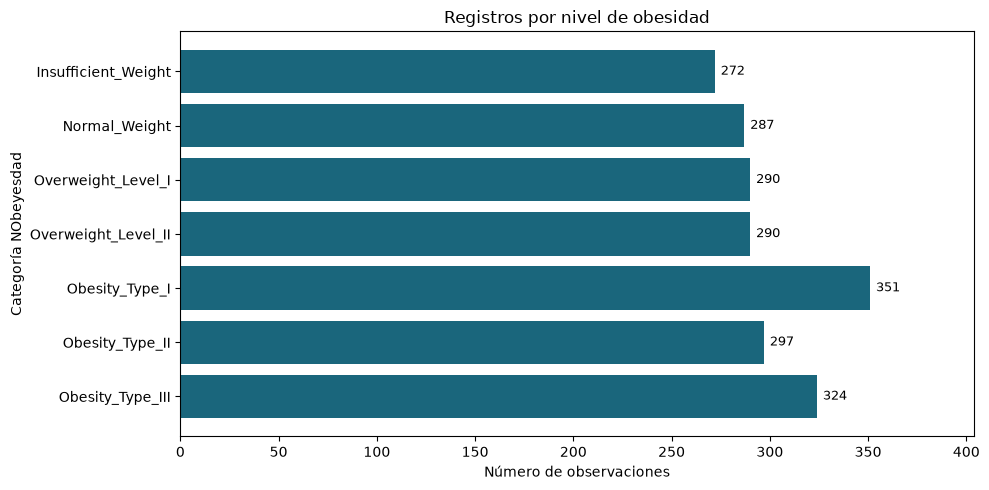

,Registros
NObeyesdad,
Insufficient_Weight,272
Normal_Weight,287
Overweight_Level_I,290
Overweight_Level_II,290
Obesity_Type_I,351
Obesity_Type_II,297
Obesity_Type_III,324


In [16]:
clases_orden = ['Insufficient_Weight','Normal_Weight','Overweight_Level_I',
                 'Overweight_Level_II','Obesity_Type_I','Obesity_Type_II','Obesity_Type_III']
conteos_clases = df['NObeyesdad'].value_counts().reindex(clases_orden)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(conteos_clases.index, conteos_clases.values, color='#1a667c')
ax.set(title='Registros por nivel de obesidad',xlabel='Número de observaciones',ylabel='Categoría NObeyesdad')
for i,v in enumerate(conteos_clases.values): ax.text(v+3,i,str(v),va='center',fontsize=9)
ax.invert_yaxis();ax.set_xlim(0,max(conteos_clases)*1.15);plt.tight_layout();plt.show()
display(conteos_clases.rename('Registros').to_frame())

**Interpretación.** `Obesity_Type_I` tiene 351 registros, mientras que `Insufficient_Weight` tiene 272. Todas las siete clases están representadas y sus conteos suman 2,111. No son porcentajes de prevalencia poblacional.

### Figura 2. Histogramas: distribución de edad, estatura y peso

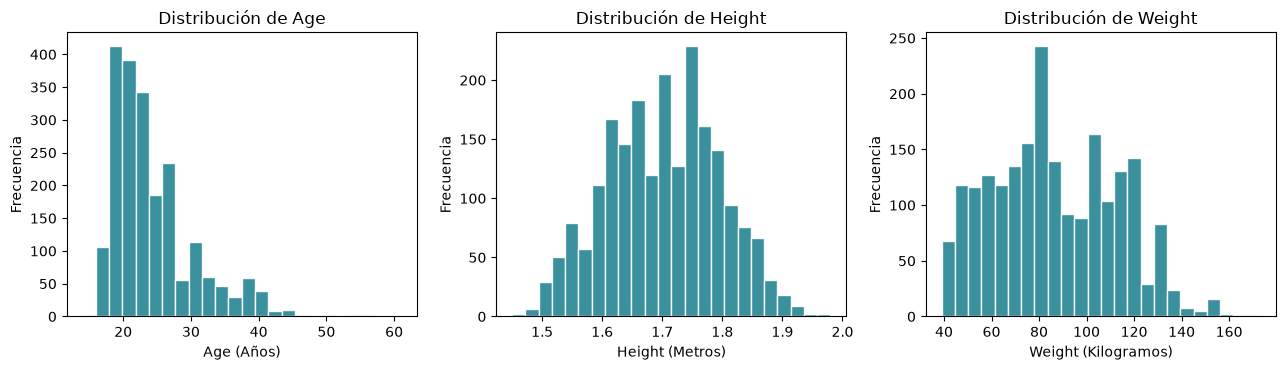

In [17]:
fig, axs = plt.subplots(1,3,figsize=(13,3.8))
for ax, col, unidad in zip(axs, ['Age','Height','Weight'], ['Años','Metros','Kilogramos']):
    ax.hist(df[col],bins=24,color='#2a8795',edgecolor='white',alpha=.92)
    ax.set(title=f'Distribución de {col}',xlabel=f'{col} ({unidad})',ylabel='Frecuencia')
plt.tight_layout();plt.show()

**Interpretación.** La edad se concentra entre adultos jóvenes, la estatura alrededor de 1.70 m y el peso tiene dispersión amplia. Un histograma permite identificar asimetrías y concentraciones, sin afirmar causalidad.

### Figura 3. Boxplots: extremos y dispersión de tres variables

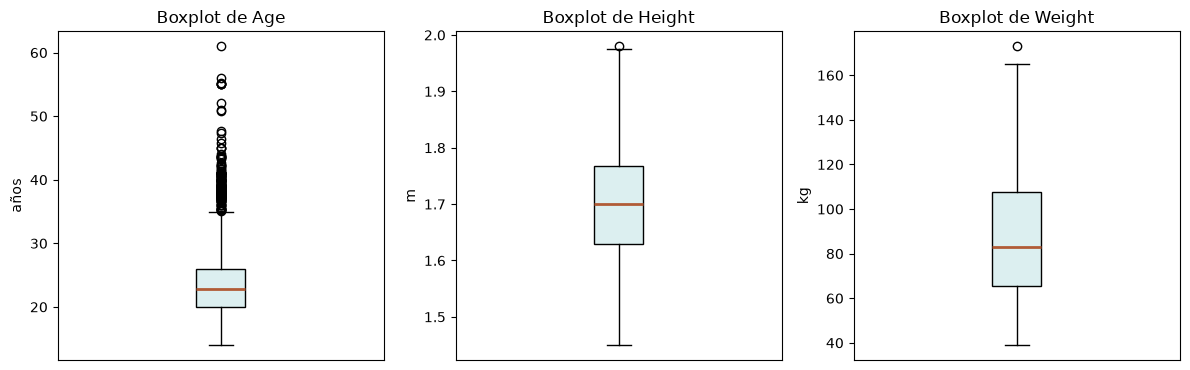

In [18]:
fig,axs=plt.subplots(1,3,figsize=(12,3.8))
for ax,col,unidad in zip(axs,['Age','Height','Weight'],['años','m','kg']):
    ax.boxplot(df[col],patch_artist=True,boxprops={'facecolor':'#dceff0'},medianprops={'color':'#b15b36','linewidth':2})
    ax.set(title=f'Boxplot de {col}',ylabel=unidad,xticks=[])
plt.tight_layout();plt.show()

**Interpretación.** Las marcas fuera de los bigotes son **candidatos IQR**: 168 en edad, 1 en estatura y 1 en peso. Los valores no se descartan; se revisaría su plausibilidad contextual antes de decidir una transformación.

### Figura 4. Dispersión: relación descriptiva estatura-peso

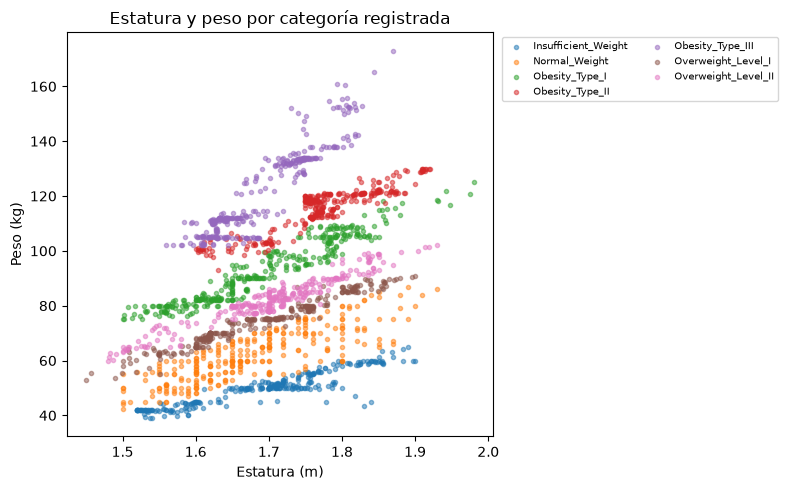

In [19]:
fig,ax=plt.subplots(figsize=(8,5))
for clase, sub in df.groupby('NObeyesdad'):
    ax.scatter(sub['Height'],sub['Weight'],s=9,alpha=.5,label=clase)
ax.set(title='Estatura y peso por categoría registrada',xlabel='Estatura (m)',ylabel='Peso (kg)')
ax.legend(fontsize=7,ncol=2,loc='upper left',bbox_to_anchor=(1.01,1))
plt.tight_layout();plt.show()

**Interpretación.** Peso y estatura presentan patrones asociados a las categorías, lo cual es esperable porque las etiquetas están relacionadas con medidas antropométricas. El gráfico es descriptivo; no demuestra causalidad ni asegura capacidad de predicción fuera de esta muestra.

## 9. Propuestas para análisis posteriores (sin entrenar modelos)

**Regresión — variable objetivo `Weight` (kg).** Proponer entradas como `Age`, `Height`, `Gender`, `FCVC`, `NCP`, `CH2O`, `FAF`, `TUE` y hábitos relevantes. No usar `Weight` como predictor de sí misma. Comparar una línea base con métodos supervisados; definir particiones que mantengan filas idénticas juntas.

**Clasificación — variable objetivo `NObeyesdad` (siete clases).** Proponer entradas como edad, antecedentes familiares y hábitos alimentarios y de actividad. La inclusión de `Weight` y `Height` facilita mucho la predicción, pero introduce riesgo de circularidad porque las etiquetas están relacionadas con esas medidas. Evaluar explícitamente **escenario A con medidas** y **escenario B sin ellas**, evitando interpretar la primera precisión como un hallazgo independiente.

**Agrupamiento — sin variable objetivo.** Seleccionar `Age`, `FCVC`, `NCP`, `CH2O`, `FAF`, `TUE` y, cuando se justifique, variables categóricas codificadas como `MTRANS` y `CAEC`. En una etapa posterior, escalar y codificar adecuadamente, estudiar grupos y revisar si representan patrones interpretables. No incluir `NObeyesdad` como variable de entrada al clustering si se busca descubrimiento no supervisado.

Estas tres propuestas responden al propósito del proyecto: describir hábitos y condición física vinculados con niveles de obesidad, respetando límites observacionales y sintéticos.

## 10. Conclusión del diagnóstico — diez preguntas de la guía

1. **¿Qué información contiene?** 2,111 observaciones y 17 variables de características físicas, hábitos, actividades y siete etiquetas de peso/obesidad.
2. **¿Cuál es su calidad general?** La estructura es consistente, con tipos legibles y sin valores faltantes; requiere cautela por duplicados y datos sintéticos.
3. **¿Qué problemas se identificaron?** 24 filas duplicadas (1.14% del total), valores fraccionarios en escalas y candidatos estadísticos IQR; no se observaron dominios inválidos ni tipos técnicos inesperados en los controles ejecutados.
4. **¿Qué variables requieren tratamiento?** En modelado posterior, las escalas codificadas y variables categóricas necesitarán tratamiento semántico y codificación apropiada; los duplicados deben controlarse al particionar.
5. **¿Existen faltantes?** No: 0 de 35,887 celdas.
6. **¿Existen registros duplicados?** Sí: 24 filas exactamente repetidas (1.14% del total); se conservaron.
7. **¿Existen valores atípicos?** Sí, candidatos por IQR en Age (168), Height (1), Weight (1) y NCP (579); no son errores confirmados.
8. **¿Qué transformaciones serán necesarias?** Si se entrena, codificar categorías, escalar según el modelo y evaluar variables, siempre evitando fugas del conjunto de prueba. No aplicar estas operaciones todavía.
9. **¿Sirven para continuar?** Sí, para análisis descriptivos, modelos supervisados y exploración de grupos con validación rigurosa y limitaciones explícitas.
10. **¿Qué conocimiento podría obtenerse?** Patrones descriptivos de hábitos y condición física asociados con etiquetas de obesidad y sus posibles agrupamientos; nunca conclusiones causales a partir de esta base.

**Cierre:** no se alteró el dataset original; todas las observaciones se conservaron. La finalidad de AE1 es diagnosticar, no limpiar ni entrenar modelos.

## Referencias y reproducibilidad

- UCI Machine Learning Repository. (2019). *Estimation of Obesity Levels Based On Eating Habits and Physical Condition* (Dataset 544). https://doi.org/10.24432/C5H31Z
- Mendoza Palechor, F., & de la Hoz Manotas, A. (2019). Dataset for estimation of obesity levels based on eating habits and physical condition in individuals from Colombia, Peru and Mexico. *Data in Brief, 25*, 104344. https://doi.org/10.1016/j.dib.2019.104344
- Archivo local de origen: `data/raw/ObesityDataSet_raw_and_data_sinthetic.csv`.

**Control final del original (lectura y hash):**

In [20]:
print('Archivo original existe:', ruta_csv.is_file())
print('SHA-256 al terminar:', sha256(ruta_csv.read_bytes()).hexdigest())
print('Conservación de origen:', sha256(ruta_csv.read_bytes()).hexdigest() == sha_original)
print('Dimensiones:', df.shape)

Archivo original existe: True
SHA-256 al terminar: 28b6991062855d3d15642e38b1aa9d1b32fb7abbb5abf5b096f1868cd706154b
Conservación de origen: True
Dimensiones: (2111, 17)
